# Etapa 1 — Contexto y calibración

Esquema v1, etapa 1. Se trabaja **solo con las 30 imágenes de desarrollo** (`dev_ids()`); las de prueba están bloqueadas.

## Preguntas

1. **¿Qué grosor tienen los vasos?** Fija los límites entre vasos finos, medianos y gruesos que usa la evaluación (plan, sección 5) y las escalas de los filtros de la etapa 4.
2. **¿Qué tamaño tiene el campo de visión?** Permite expresar grosores y escalas en proporción a su diámetro, para que el algoritmo funcione con otras resoluciones.
3. **¿Se puede detectar el campo de visión solo?** Las imágenes de la cátedra pueden venir sin máscara.

Además, a modo descriptivo: tamaño aproximado del píxel e iluminación del fondo.

## Reglas fijadas antes de correr

**Grosor.**
- En cada máscara de los expertos, dentro del campo de visión de la base, se calcula la línea central (esqueleto) y el ancho en cada punto: 2 × (distancia al fondo) − 1 (`skeleton_widths`).
- Los límites son los **terciles del ancho sobre la línea central, juntando las 30 imágenes**: cada clase tiene un tercio de la longitud total de vasos. Es una decisión de criterio: con píxeles pesarían más los vasos gruesos.
- Clases: fino si ancho ≤ primer límite; grueso si ancho > segundo límite; mediano en el medio. Se informa qué fracción de la longitud quedó en cada clase.
- Los límites se guardan en `config.py`, en píxeles y en proporción al diámetro del campo de visión, y no se cambian más. Son los mismos para todas las imágenes.

**Diámetro.** Ancho horizontal del campo de visión de la base (`fov_diameter`).

**Campo de visión automático** (`detect_fov`).
- Candidata 1: umbral de Otsu sobre el canal rojo, región más grande, relleno de huecos (margen 0).
- Candidata 2: lo mismo con un margen de *m* píxeles (positivo achica el borde, negativo lo agranda). *m* se elige entre −8 y 8 como el que maximiza el peor coeficiente de Dice de las 30 imágenes.
- Se adopta la más simple cuyo coeficiente de Dice con la máscara de la base sea **≥ 0,99 en todas** las imágenes de desarrollo. Si ninguna lo logra, el algoritmo usa la máscara de la base y se declara como limitación para imágenes sin máscara.
- La evaluación usa siempre la máscara de la base.


In [1]:
import sys
from pathlib import Path

ROOT = Path.cwd().parent if Path.cwd().name == "notebooks" else Path.cwd()
sys.path.insert(0, str(ROOT))

import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
from scipy import ndimage as ndi

from src.config import RESULTS_DIR
from src.data import dev_ids, load_fov, load_image, load_split, load_vessels
from src.fov import detect_fov, fov_diameter
from src.metrics import dice
from src.vessels import skeleton_widths, width_classes, width_map

pd.set_option("display.precision", 3)
ids = dev_ids()
split = load_split().set_index("image")
print(len(ids), "imágenes de desarrollo")

30 imágenes de desarrollo


## Cálculo por imagen

Para cada imagen: diámetro del campo de visión, anchos sobre la línea central, detección automática del campo de visión con márgenes de −8 a 8 y brillo del fondo por anillos (fuera de los vasos, ensanchados 5 píxeles).

In [2]:
MARGINS = range(-8, 9)
RINGS = np.linspace(0, 1, 6)            # anillos por distancia al centro / radio
rows, widths_by_image, dice_rows, ring_rows = [], {}, [], []

for image_id in ids:
    rgb, fov, ves = load_image(image_id), load_fov(image_id), load_vessels(image_id)
    v = ves & fov
    skel, widths = skeleton_widths(v)
    widths_by_image[image_id] = widths[skel]
    diam = fov_diameter(fov)

    base = detect_fov(rgb)
    din, dout = ndi.distance_transform_edt(base), ndi.distance_transform_edt(~base)
    for m in MARGINS:
        auto = base if m == 0 else (din > m if m > 0 else dout <= -m)
        dice_rows.append({"image": image_id, "margin": m, "dice": dice(auto, fov)})

    yy, xx = np.nonzero(fov)
    cy, cx = yy.mean(), xx.mean()
    r = np.hypot(*np.mgrid[:fov.shape[0], :fov.shape[1]] - np.array([cy, cx])[:, None, None]) / (diam / 2)
    background = fov & ~ndi.binary_dilation(ves, iterations=5)
    for k in range(len(RINGS) - 1):
        ring = background & (r >= RINGS[k]) & (r < RINGS[k + 1])
        ring_rows.append({"image": image_id, "ring": k,
                          **{c: float(np.median(rgb[..., i][ring])) for i, c in enumerate("rgb")}})

    rows.append({"image": image_id, "group": split.loc[image_id, "group"],
                 "more_compressed": split.loc[image_id, "more_compressed"],
                 "fov_diameter": diam, "fov_height": int(fov.any(axis=1).sum()),
                 "vessel_fraction": v[fov].mean(), "skeleton_length": int(skel.sum()),
                 "median_width": float(np.median(widths[skel]))})

per_image = pd.DataFrame(rows).set_index("image")
dice_df = pd.DataFrame(dice_rows)
rings = pd.DataFrame(ring_rows)
RESULTS_DIR.mkdir(exist_ok=True)
per_image.to_csv(RESULTS_DIR / "01_por_imagen.csv")
np.savez_compressed(RESULTS_DIR / "01_anchos.npz", **widths_by_image)
per_image

,group,more_compressed,fov_diameter,fov_height,vessel_fraction,skeleton_length,median_width
image,,,,,,,
01_h,h,False,3263,2336,0.121,75057,7.000
02_h,h,False,3263,2336,0.117,67613,9.000
03_h,h,False,3262,2336,0.125,67996,9.000
04_h,h,False,3263,2336,0.112,65210,9.000
07_h,h,True,3262,2336,0.105,63508,7.944
08_h,h,True,3262,2336,0.119,70976,7.246
09_h,h,True,3262,2336,0.092,64372,6.211
10_h,h,True,3262,2336,0.102,72811,6.211
13_h,h,True,3262,2336,0.103,60666,7.246


## Pregunta 2: diámetro del campo de visión

In [3]:
print(per_image[["fov_diameter", "fov_height"]].describe().loc[["min", "50%", "max"]])
D = int(per_image["fov_diameter"].median())
print(f"\nDiámetro de referencia (mediana): {D} píxeles")

     fov_diameter  fov_height
min        3261.0      2336.0
50%        3262.0      2336.0
max        3263.0      2336.0

Diámetro de referencia (mediana): 3262 píxeles


## Pregunta 1: grosor de los vasos

In [4]:
all_w = np.concatenate(list(widths_by_image.values()))
t1, t2 = np.quantile(all_w, [1 / 3, 2 / 3])
cls = np.where(all_w <= t1, "fino", np.where(all_w > t2, "grueso", "mediano"))
share = pd.Series(cls).value_counts(normalize=True).reindex(["fino", "mediano", "grueso"])

print(f"Puntos de línea central: {all_w.size:,}")
print(f"Terciles del ancho: {t1:.2f} y {t2:.2f} píxeles")
print(f"En proporción al diámetro: {t1 / D:.5f} y {t2 / D:.5f}")
print("\nFracción de la longitud en cada clase:")
print(share.round(3).to_string())
print("\nPercentiles del ancho (píxeles):")
print(pd.Series(np.percentile(all_w, [5, 25, 50, 75, 95, 99]), index=[5, 25, 50, 75, 95, 99]).round(2).to_string())

Puntos de línea central: 2,066,520
Terciles del ancho: 3.47 y 9.00 píxeles
En proporción al diámetro: 0.00106 y 0.00276

Fracción de la longitud en cada clase:
fino       0.376
mediano    0.312
grueso     0.312

Percentiles del ancho (píxeles):
5      1.00
25     3.00
50     5.32
75    11.00
95    19.59
99    25.91


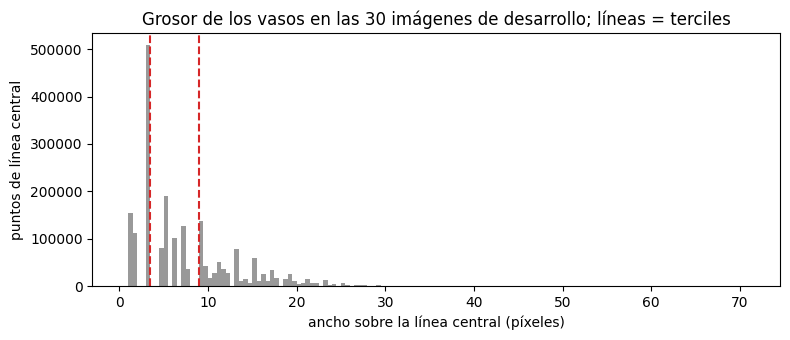

In [5]:
fig, ax = plt.subplots(figsize=(8, 3.5))
ax.hist(all_w, bins=np.arange(0.5, all_w.max() + 1, 0.5), color="0.6")
for t in (t1, t2):
    ax.axvline(t, color="C3", ls="--")
ax.set_xlabel("ancho sobre la línea central (píxeles)")
ax.set_ylabel("puntos de línea central")
ax.set_title("Grosor de los vasos en las 30 imágenes de desarrollo; líneas = terciles")
plt.tight_layout()

**Por grupo y por compresión** (solo descriptivo): longitud de línea central de cada clase, con los límites comunes.

In [6]:
def class_share(w):
    return pd.Series({"fino": np.mean(w <= t1), "mediano": np.mean((w > t1) & (w <= t2)),
                      "grueso": np.mean(w > t2)})

by_img = pd.DataFrame({i: class_share(w) for i, w in widths_by_image.items()}).T
by_img = by_img.join(per_image[["group", "more_compressed"]])
print(by_img.groupby("group")[["fino", "mediano", "grueso"]].mean().round(3))
print()
print(by_img.groupby(["group", "more_compressed"])[["fino", "mediano", "grueso"]].mean().round(3))

        fino  mediano  grueso
group                        
dr     0.451    0.275   0.275
g      0.455    0.284   0.261
h      0.210    0.383   0.408

                        fino  mediano  grueso
group more_compressed                        
dr    False            0.438    0.281   0.281
      True             0.500    0.250   0.250
g     False            0.456    0.270   0.274
      True             0.454    0.304   0.242
h     False            0.152    0.416   0.432
      True             0.248    0.360   0.392


**Qué pasa al reducir la resolución:** ancho de los límites en píxeles a la mitad y a la cuarta parte.

In [7]:
print(pd.DataFrame({"original": [t1, t2], "mitad": [t1 / 2, t2 / 2], "cuarta parte": [t1 / 4, t2 / 4]},
                   index=["límite fino", "límite grueso"]).round(2))
print(f"\nFracción de la longitud con ancho ≤ 2 píxeles a la mitad: {np.mean(all_w / 2 <= 2):.3f}")
print(f"Fracción de la longitud con ancho ≤ 2 píxeles a la cuarta parte: {np.mean(all_w / 4 <= 2):.3f}")

               original  mitad  cuarta parte
límite fino        3.47   1.74          0.87
límite grueso      9.00   4.50          2.25

Fracción de la longitud con ancho ≤ 2 píxeles a la mitad: 0.376
Fracción de la longitud con ancho ≤ 2 píxeles a la cuarta parte: 0.634


**Ejemplo:** clases de grosor en una imagen de desarrollo.

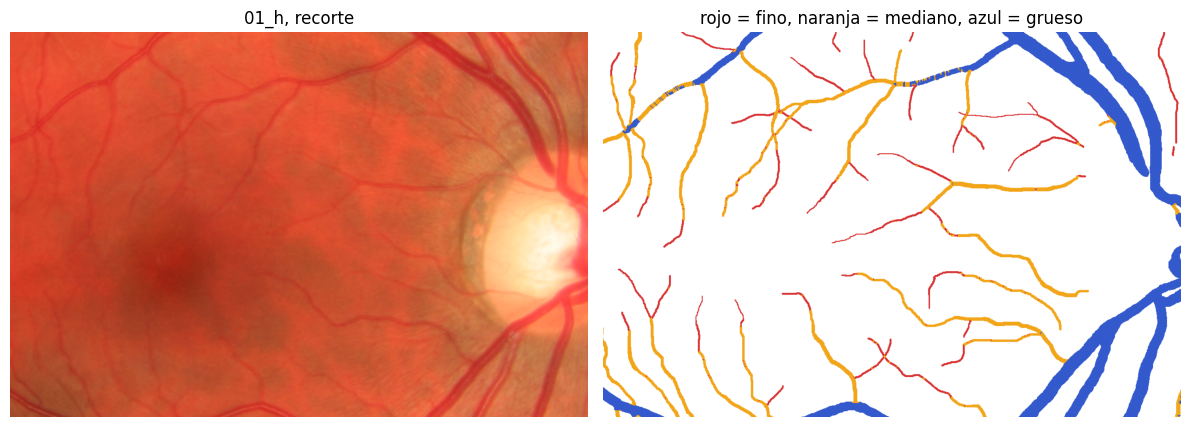

In [8]:
ex = ids[0]
v_ex = load_vessels(ex) & load_fov(ex)
classes = width_classes(width_map(v_ex), (t1, t2))
crop = (slice(700, 1500), slice(1500, 2700))
colors = np.array([[1, 1, 1], [0.85, 0.2, 0.2], [0.95, 0.65, 0.1], [0.2, 0.35, 0.8]])
fig, ax = plt.subplots(1, 2, figsize=(12, 4.2))
ax[0].imshow(load_image(ex)[crop]); ax[0].set_title(f"{ex}, recorte")
ax[1].imshow(colors[classes[crop]]); ax[1].set_title("rojo = fino, naranja = mediano, azul = grueso")
for a in ax: a.axis("off")
plt.tight_layout()

## Pregunta 3: campo de visión automático

In [9]:
m0 = dice_df[dice_df.margin == 0].set_index("image")["dice"]
print(f"Margen 0: Dice mínimo {m0.min():.4f}, mediana {m0.median():.4f}; "
      f"imágenes con Dice < 0,99: {int((m0 < 0.99).sum())}")
worst = dice_df.groupby("margin")["dice"].agg(["min", "median"])
best_m = int(worst["min"].idxmax())
print(f"\nMargen que maximiza el peor Dice: {best_m} (peor Dice {worst.loc[best_m, 'min']:.4f})")
worst.T.round(4)

Margen 0: Dice mínimo 0.9543, mediana 0.9991; imágenes con Dice < 0,99: 1

Margen que maximiza el peor Dice: -8 (peor Dice 0.9602)


margin,-8,-7,-6,-5,-4,-3,-2,-1,0,1,2,3,4,5,6,7,8
min,0.960,0.960,0.959,0.959,0.958,0.957,0.956,0.955,0.954,0.953,0.952,0.951,0.951,0.950,0.949,0.949,0.948
median,0.998,0.998,0.998,0.999,0.999,0.999,1.000,1.000,0.999,0.999,0.998,0.998,0.998,0.997,0.997,0.996,0.996


In [10]:
print("Las 5 imágenes con menor Dice (margen 0):")
print(m0.sort_values().head().round(4).to_string())

Las 5 imágenes con menor Dice (margen 0):
image
14_h     0.954
04_h     0.992
07_g     0.995
06_dr    0.995
04_dr    0.996


**Por qué falla en la peor imagen.** En la imagen con menor Dice, la periferia es mucho más oscura que el centro y el umbral de Otsu cae entre el centro brillante y la periferia, no entre la retina y el negro de afuera.

14_h: umbral de Otsu 97; rojo mediano en la zona que falta 84; rojo mediano afuera 0


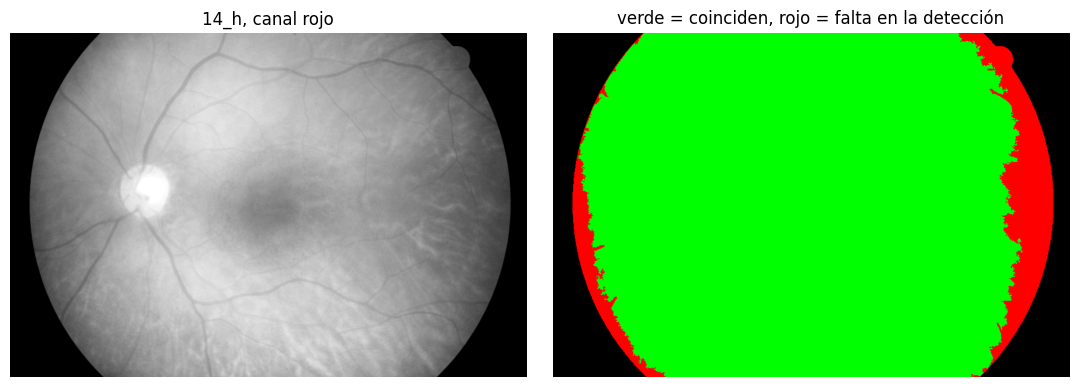

In [11]:
bad = m0.idxmin()
rgb_b, fov_b = load_image(bad), load_fov(bad)
auto_b = detect_fov(rgb_b)
from skimage.filters import threshold_otsu
print(f"{bad}: umbral de Otsu {threshold_otsu(rgb_b[::4, ::4, 0]):.0f}; "
      f"rojo mediano en la zona que falta {np.median(rgb_b[..., 0][fov_b & ~auto_b]):.0f}; "
      f"rojo mediano afuera {np.median(rgb_b[..., 0][~fov_b]):.0f}")
f = 4
ov = np.zeros(fov_b[::f, ::f].shape + (3,))
ov[..., 1] = (fov_b & auto_b)[::f, ::f]; ov[..., 0] = (fov_b & ~auto_b)[::f, ::f]; ov[..., 2] = (auto_b & ~fov_b)[::f, ::f]
fig, ax = plt.subplots(1, 2, figsize=(11, 3.8))
ax[0].imshow(rgb_b[::f, ::f, 0], cmap="gray"); ax[0].set_title(f"{bad}, canal rojo")
ax[1].imshow(ov); ax[1].set_title("verde = coinciden, rojo = falta en la detección")
for a in ax: a.axis("off")
plt.tight_layout()

## Correspondencia entre las máscaras y las imágenes

La tabla por grupo de la pregunta 1 muestra que las máscaras de sanos tienen vasos más anchos y menos longitud fina que las de los otros grupos. Para ver si es la retina o la forma de marcar, se mide **qué tan oscuro es el borde de la máscara**: en los vasos medianos y gruesos (ancho ≥ 5), el verde del anillo más externo de la máscara se compara con el fondo justo afuera (2 a 4 píxeles) y con la línea central del vaso.

- 0 = el borde de la máscara es tan claro como el fondo (la máscara es más ancha que el vaso visible);
- 1 = el borde es tan oscuro como el centro del vaso (la máscara es más angosta o justa).

Es un indicio, no una prueba: la compresión y el enfoque también cambian lo nítido del borde.

In [12]:
edge_rows = []
for image_id in ids:
    g = load_image(image_id)[..., 1].astype(float)
    fov = load_fov(image_id)
    v = load_vessels(image_id) & fov
    skel, w = skeleton_widths(v)
    din, dout = ndi.distance_transform_edt(v), ndi.distance_transform_edt(~v)
    inner = ndi.binary_erosion(fov, iterations=20)
    big = skel & (w >= 5)
    near = ndi.binary_dilation(big, iterations=15) & inner
    out = np.median(g[(~v) & (dout >= 2) & (dout <= 4) & near])
    edge = np.median(g[v & (din == 1) & near])
    center = np.median(g[big & inner])
    edge_rows.append({"image": image_id, "borde": (out - edge) / (out - center)})
edge_df = pd.DataFrame(edge_rows).set_index("image").join(per_image[["group", "more_compressed", "median_width", "vessel_fraction"]])
print(edge_df.groupby("group")[["borde", "median_width", "vessel_fraction"]].agg(["mean", "min", "max"]).round(3).T)
print()
print(edge_df.groupby(["group", "more_compressed"])["borde"].mean().round(2))

group                    dr      g      h
borde           mean  0.737  0.626  0.501
                min   0.571  0.375  0.400
                max   1.000  0.727  0.600
median_width    mean  4.846  4.809  7.634
                min   3.472  3.472  6.211
                max   6.211  5.325  9.000
vessel_fraction mean  0.085  0.081  0.110
                min   0.067  0.068  0.092
                max   0.103  0.098  0.125

group  more_compressed
dr     False              0.71
       True               0.86
g      False              0.65
       True               0.59
h      False              0.52
       True               0.49
Name: borde, dtype: float64


## Contexto descriptivo

**Tamaño aproximado del píxel.** Según Budai et al. (2013), las fotos se sacaron con un retinógrafo Canon CR-1 con 45° de campo (los archivos dicen Canon EOS 20D, que es la cámara montada en el retinógrafo). Con la equivalencia aproximada de 0,29 mm de retina por grado en un ojo promedio, 45° son unos 13 mm a lo ancho del campo de visión. **Es una estimación aproximada**: depende del largo del ojo de cada persona.

In [13]:
MM_PER_DEG = 0.29     # supuesto aproximado, ojo promedio
um_px = 45 * MM_PER_DEG * 1000 / D
print(f"≈ {um_px:.1f} micrómetros por píxel")
print(f"Límites de grosor ≈ {t1 * um_px:.0f} y {t2 * um_px:.0f} micrómetros")

≈ 4.0 micrómetros por píxel
Límites de grosor ≈ 14 y 36 micrómetros


**Iluminación del fondo.** Mediana de cada canal fuera de los vasos, en anillos desde el centro (0) hasta el borde (4) del campo de visión, dividida por la del anillo central. Mediana de las 30 imágenes.

In [14]:
rel = rings.set_index(["image", "ring"])
rel = rel / rel.xs(0, level="ring").reindex(rel.index, level="image").values
print(rel.groupby(level="ring").median().round(2).rename(columns={"r": "rojo", "g": "verde", "b": "azul"}))

      rojo  verde  azul
ring                   
0     1.00   1.00  1.00
1     1.15   1.16  1.12
2     1.18   1.21  1.13
3     1.10   1.02  0.91
4     0.87   0.73  0.65


## Decisión (escrita después de correr)

**1. Límites de grosor: 3,47 y 9 píxeles** (0,00106 y 0,00276 del diámetro del campo de visión; unos 14 y 36 micrómetros, con el tamaño de píxel aproximado). Fino ≤ 3,47; mediano entre 3,47 y 9; grueso > 9. Como los anchos se concentran en pocos valores, las clases quedaron con 37,6 %, 31,2 % y 31,2 % de la longitud, no exactamente un tercio. Se guardan en `config.py` (`WIDTH_LIMITS_PX`, `WIDTH_LIMITS_REL`) y no se cambian más.

**2. Diámetro del campo de visión: 3.262 píxeles** (3.261 a 3.263 en las 30 imágenes). El campo de visión ocupa todo el alto de la imagen (2.336 píxeles): es un círculo recortado arriba y abajo. Se guarda como `FOV_DIAMETER_REF`; las escalas de los filtros se expresan en proporción a él.

**3. Campo de visión automático: no se adopta.** Con margen 0, 29 de las 30 imágenes superan 0,99 (mediana 0,999), pero una queda en 0,954: su periferia es oscura y el umbral de Otsu cae entre el centro y la periferia. Ningún margen la corrige (el mejor peor caso es 0,960). Según la regla, el algoritmo usa la máscara de la base (`USE_AUTO_FOV = False`) y se declara como limitación para imágenes sin máscara. Una candidata nueva (por ejemplo, un umbral bajo fijo en el rojo) solo se puede probar como desvío declarado.

**4. Resolución (no se decide acá).** A la mitad, el límite de fino queda en 1,7 píxeles y el 38 % de la longitud de vasos mide 2 píxeles o menos; a la cuarta parte, el 63 %. Reducir puede perder vasos finos; se decide en las etapas 2 a 4, siempre evaluando a resolución original.

**5. Iluminación.** El fondo es más oscuro en el centro (la mácula) y sobre todo en el borde: en el anillo exterior el verde cae al 73 % y el azul al 65 % del centro. Hace falta la corrección del fondo de la etapa 3.

**6. Hallazgo: las máscaras de sanos están marcadas más anchas.** En desarrollo, las de sanos tienen ancho mediano de 6 a 9 píxeles contra unos 5 en retinopatía, 21 % de longitud fina contra 45 %, y su borde es más claro (0,50 contra 0,74 en retinopatía y 0,63 en glaucoma). No depende de la compresión dentro de sanos. Lo más probable es una **diferencia en la forma de marcar**, no en la retina. Consecuencias:
- la diferencia de proporción de vasos entre sanos y retinopatía (alrededor de 11 % contra 8 %) puede ser en buena parte de las máscaras, y hay que tenerlo en cuenta en la etapa 7;
- un algoritmo que marque los vasos con el mismo ancho en todas las imágenes va a parecer peor en sanos o en retinopatía por esta razón, no por la enfermedad (etapa 6);
- conviene agregar una medida que no dependa del ancho marcado, basada en la línea central. Se propone como desvío del plan.
